# Notebook #05 — Unsupervised Discovery (K-Means + Seed ARI, PCA 3D, Isolation Forest, FP-Growth)

### Mục tiêu khám phá tri thức
1. **K-Means (`k=4`) & Seed Stability:** Quét `k=2..8` với Elbow, Silhouette, Davies-Bouldin, Calinski-Harabasz và kiểm tra đồng thuận giữa 5 seed `[0, 7, 21, 42, 99]` bằng **Adjusted Rand Index (ARI)** (ARI đo độ ổn định phân cụm, không phải accuracy).
2. **PCA 3D:** Giảm chiều để quan sát phân tách không gian đặc trưng (`52.40%` tổng phương sai).
3. **Isolation Forest:** Phát hiện 3% chuyến bay có điều kiện vận hành/thời tiết dị thường và kiểm chứng tỷ lệ gián đoạn hậu kiểm theo sân bay/hãng.
4. **FP-Growth Association Rules:** Lọc luật dư thừa (`Redundancy Pruning`) và kiểm tra tính tái lập trên tập **Holdout Test**.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

from flight_delay.common.constants import FILE_RULES

uns = json.loads(Path("reports/experiments/unsupervised_results.json").read_text(encoding="utf-8"))
km = uns["kmeans"]
pca = uns["pca"]
iso = uns["isolation_forest"]

print(f"K-Means k={km['k_selected']} | 5-Seed Stability ARI: mean={km['seed_stability']['ari_mean']} (min={km['seed_stability']['ari_min']})")
print("\n=== Cluster Operational Regimes ===")
print(pd.DataFrame(km["cluster_profiles"])[["cluster_id", "name", "count", "share_pct", "avg_airport_load", "delay_rate_pct", "cancel_rate_pct"]].to_string(index=False))

print(f"\nPCA 3D Cumulative Explained Variance: {pca['cumulative_variance_pct']}% | Ratios: {pca['explained_variance_ratio']}")
print(f"Isolation Forest: {iso['anomaly_count']} anomalies ({iso['anomaly_rate_pct']}%) | Disrupted rate: {iso['anomaly_disruption_rate_pct']}% vs normal {iso['normal_disruption_rate_pct']}%")

rules_df = pd.read_csv(FILE_RULES)
print(f"\nFP-Growth Pruned Non-Redundant Rules: {len(rules_df)} | Holdout retained delayed rules: {uns['association_rules']['per_target_summary']}")
print(rules_df[["antecedents", "consequent", "support_pct", "confidence_pct", "lift", "test_confidence_pct", "test_lift", "holdout_validated"]].head(8).to_string(index=False))

K-Means k=4 | 5-Seed Stability ARI: mean=0.7958 (min=0.4894)

=== Cluster Operational Regimes ===
 cluster_id                               name  count  share_pct  avg_airport_load  delay_rate_pct  cancel_rate_pct
          3   Giờ Cao điểm Đông tải Trục chính   3886       28.6              26.5            32.0             0.51
          0 Bất lợi Thời tiết (Mưa & Gió mạnh)   2746       20.2              24.1            28.5             0.98
          1     Điều kiện Thuận lợi / Tải thấp   5998       44.2              27.1            22.2             0.75
          2 Bất lợi Thời tiết (Mưa & Gió mạnh)    940        6.9              22.3            22.4             0.32

PCA 3D Cumulative Explained Variance: 52.4% | Ratios: [0.2332, 0.1656, 0.1252]
Isolation Forest: 408 anomalies (3.01%) | Disrupted rate: 33.33% vs normal 26.82%

FP-Growth Pruned Non-Redundant Rules: 34 | Holdout retained delayed rules: {'Status=delayed': {'raw_rules': 94, 'pruned_rules': 30, 'holdout_retained': 29}, 'S

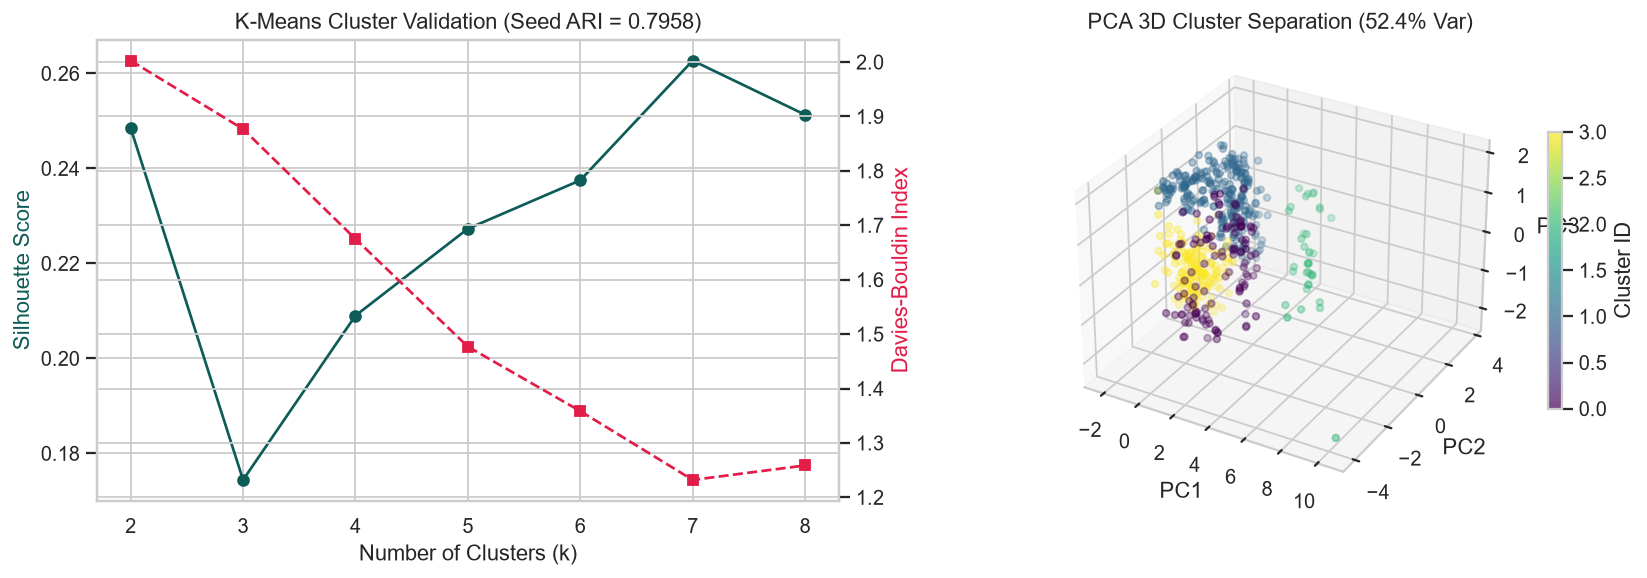

In [2]:
# Visualization: K-Means Sweep Curves + PCA 3D Scatter Projection
sweep_df = pd.DataFrame(km["k_sweep"])
pts = pd.DataFrame(pca["scatter_sample"])

fig = plt.figure(figsize=(13, 4.6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(sweep_df["k"], sweep_df["silhouette"], marker="o", color="#0d5c58", label="Silhouette (higher=better)")
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Silhouette Score", color="#0d5c58")
ax2 = ax1.twinx()
ax2.plot(sweep_df["k"], sweep_df["davies_bouldin"], marker="s", ls="--", color="#e11d48", label="Davies-Bouldin (lower=better)")
ax2.set_ylabel("Davies-Bouldin Index", color="#e11d48")
ax1.set_title(f"K-Means Cluster Validation (Seed ARI = {km['seed_stability']['ari_mean']})")

ax3 = fig.add_subplot(1, 2, 2, projection="3d")
sc = ax3.scatter(pts["pc1"], pts["pc2"], pts["pc3"], c=pts["cluster"], cmap="viridis", s=14, alpha=0.7)
ax3.set_title(f"PCA 3D Cluster Separation ({pca['cumulative_variance_pct']}% Var)")
ax3.set_xlabel("PC1")
ax3.set_ylabel("PC2")
ax3.set_zlabel("PC3")
fig.colorbar(sc, ax=ax3, shrink=0.6, label="Cluster ID")

fig.tight_layout()
plt.show()